In [ ]:
%pip install --upgrade matplotlib

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

print("All libraries imported successfully!")

OpenCV version: 5.0.0
NumPy version: 2.2.6
Matplotlib version: 3.10.9
All libraries imported successfully!


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

print("All libraries imported successfully!")

OpenCV version: 5.0.0
NumPy version: 2.2.6
Matplotlib version: 3.10.9
All libraries imported successfully!


In [5]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

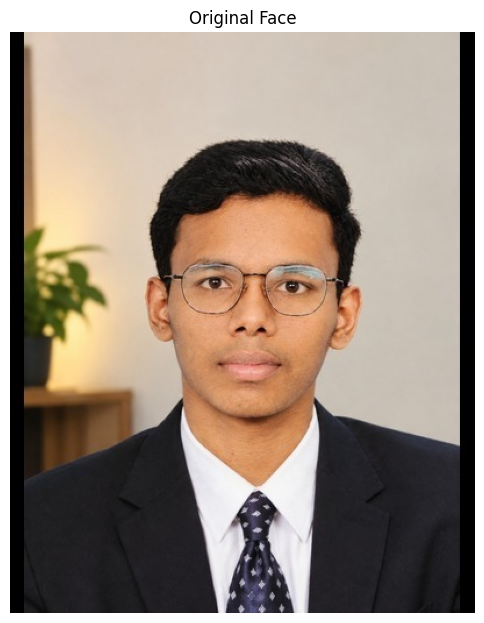

Face dimensions: (500, 400, 3)


In [7]:
# Load and display the face image
faceImage = cv2.imread("passport (1).jpg")

if faceImage is None:
    raise FileNotFoundError(
        "Cannot find myphoto.jpeg. Put it in the notebook folder."
    )

faceImage = cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(faceImage)
plt.title("Original Face")
plt.axis("off")
plt.show()

print("Face dimensions:", faceImage.shape)

In [8]:
# Check the face image dimensions
faceImage.shape

(500, 400, 3)

In [9]:
# Check the face image dimensions (same result as the previous cell)
faceImage.shape

(500, 400, 3)

In [10]:
# Resizing is handled inside add_sunglasses()
# so that the original transparency is preserved.

print("Sunglasses will be resized automatically in the overlay function.")

Sunglasses will be resized automatically in the overlay function.


Sunglasses dimensions: (273, 627, 4)


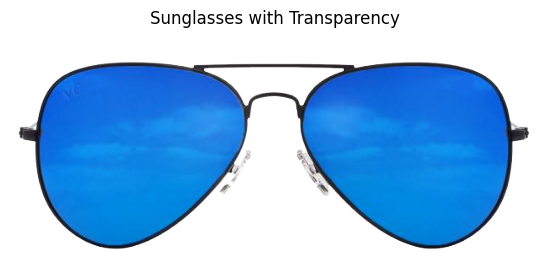

In [11]:
# Load the sunglasses PNG with its alpha (transparency) channel
glassPNG = cv2.imread('sunglass-png-aviator-sunglass-png-pic-627.png', cv2.IMREAD_UNCHANGED)

if glassPNG is None:
    raise FileNotFoundError(
        "Cannot find sunglass.png. Put it in the notebook folder."
    )

if len(glassPNG.shape) != 3 or glassPNG.shape[2] != 4:
    raise ValueError(
        "sunglass.png must be a transparent PNG with 4 channels (BGRA)."
    )

print("Sunglasses dimensions:", glassPNG.shape)

plt.figure(figsize=(8, 3))
plt.imshow(cv2.cvtColor(glassPNG, cv2.COLOR_BGRA2RGBA))
plt.title("Sunglasses with Transparency")
plt.axis("off")
plt.show()

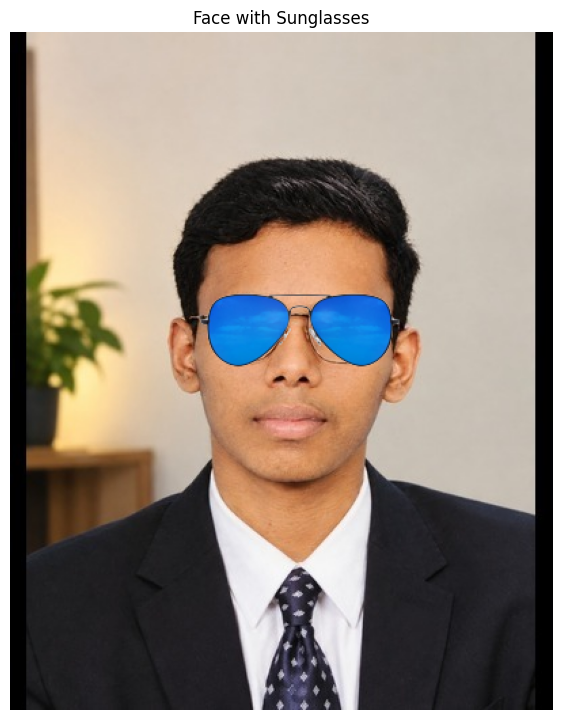

In [27]:
# Resize and blend sunglasses over the face.

def add_sunglasses(
    face,
    glasses,
    x_ratio=0.345,
    y_ratio=0.37,
    width_ratio=0.38
):
    result = face.copy()
    H, W = face.shape[:2]

    # Calculate sunglasses size while preserving aspect ratio
    glasses_width = max(1, int(W * width_ratio))
    glasses_height = max(
        1,
        int(glasses.shape[0] * glasses_width / glasses.shape[1])
    )

    glasses_resized = cv2.resize(
        glasses,
        (glasses_width, glasses_height),
        interpolation=cv2.INTER_AREA
    )

    # Position relative to the face image
    x = int(W * x_ratio)
    y = int(H * y_ratio)

    # Keep the overlay inside the image boundaries
    x1, y1 = max(0, x), max(0, y)
    x2 = min(W, x + glasses_width)
    y2 = min(H, y + glasses_height)

    if x1 >= x2 or y1 >= y2:
        return result

    # Match the corresponding sunglasses crop
    gx1, gy1 = x1 - x, y1 - y
    gx2 = gx1 + (x2 - x1)
    gy2 = gy1 + (y2 - y1)

    overlay = glasses_resized[gy1:gy2, gx1:gx2]

    # Convert sunglasses colors from BGR to RGB
    glass_rgb = cv2.cvtColor(
        overlay[:, :, :3],
        cv2.COLOR_BGR2RGB
    ).astype(np.float32)

    # Preserve the alpha transparency channel
    alpha = overlay[:, :, 3:4].astype(np.float32) / 255.0

    # Blend sunglasses with the corresponding face region
    roi = result[y1:y2, x1:x2].astype(np.float32)

    blended = roi * (1.0 - alpha) + glass_rgb * alpha

    result[y1:y2, x1:x2] = np.clip(
        blended, 0, 255
    ).astype(np.uint8)

    return result


# Apply the sunglasses
faceWithGlasses = add_sunglasses(faceImage, glassPNG)

plt.figure(figsize=(7, 9))
plt.imshow(faceWithGlasses)
plt.title("Face with Sunglasses")
plt.axis("off")
plt.show()

In [29]:
# Separate the sunglasses color and alpha channels
glassBGR = glassPNG[:, :, :3]
glassMask1 = glassPNG[:, :, 3]

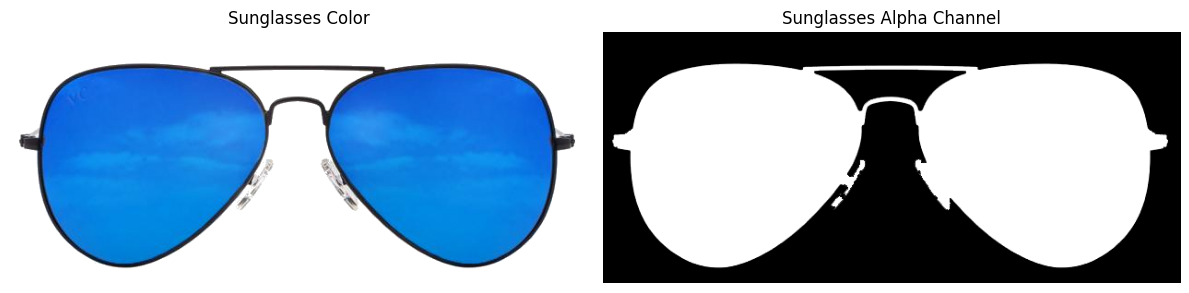

In [30]:
# Display the sunglasses color and transparency channels
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses Color")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(glassMask1, cmap="gray", vmin=0, vmax=255)
plt.title("Sunglasses Alpha Channel")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
# Display the correctly blended sunglasses
faceWithGlassesNaive = faceWithGlasses.copy()

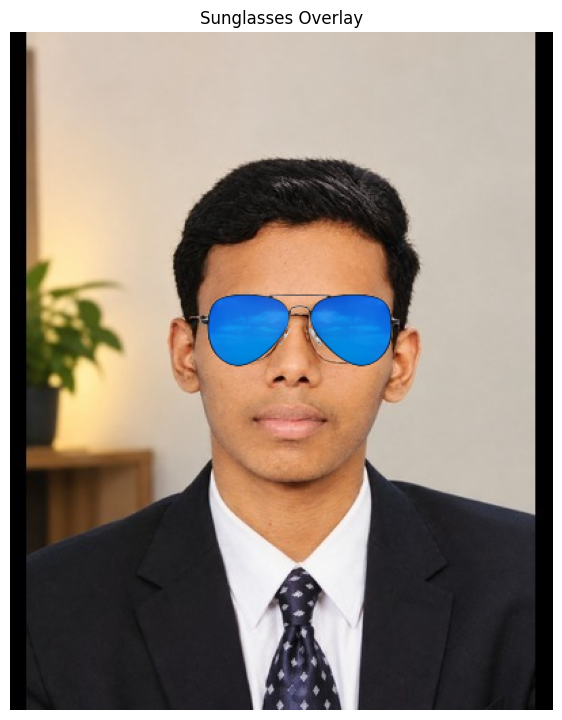

In [32]:
plt.figure(figsize=(7, 9))
plt.imshow(faceWithGlassesNaive)
plt.title("Sunglasses Overlay")
plt.axis("off")
plt.show()

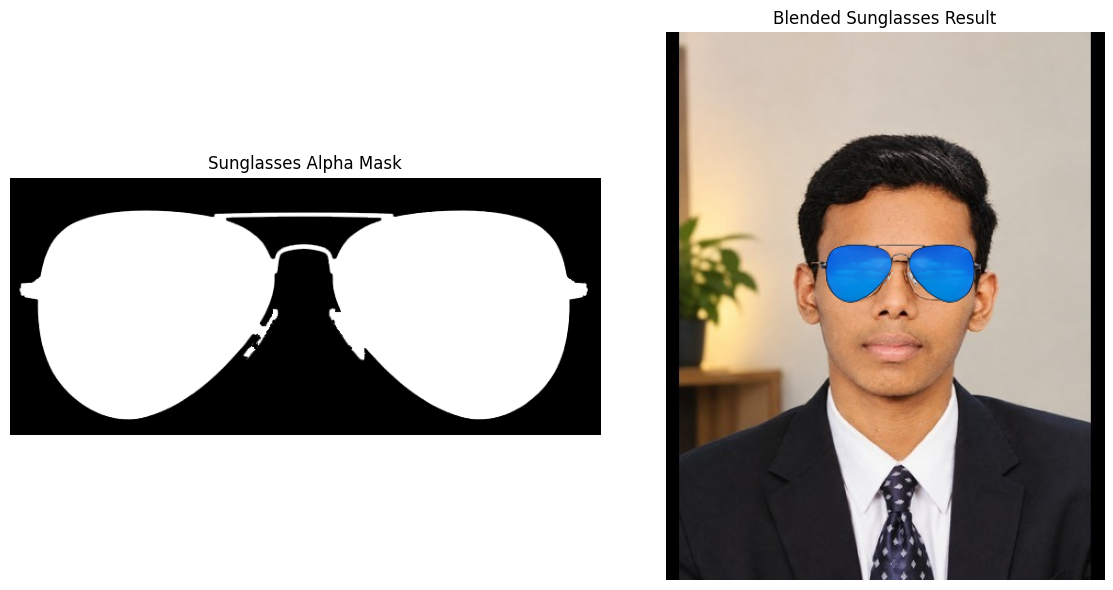

In [33]:
# Alpha-mask blending demonstration
faceWithGlassesArithmetic = add_sunglasses(
    faceImage,
    glassPNG
)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(glassMask1, cmap="gray", vmin=0, vmax=255)
plt.title("Sunglasses Alpha Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(faceWithGlassesArithmetic)
plt.title("Blended Sunglasses Result")
plt.axis("off")

plt.tight_layout()
plt.show()

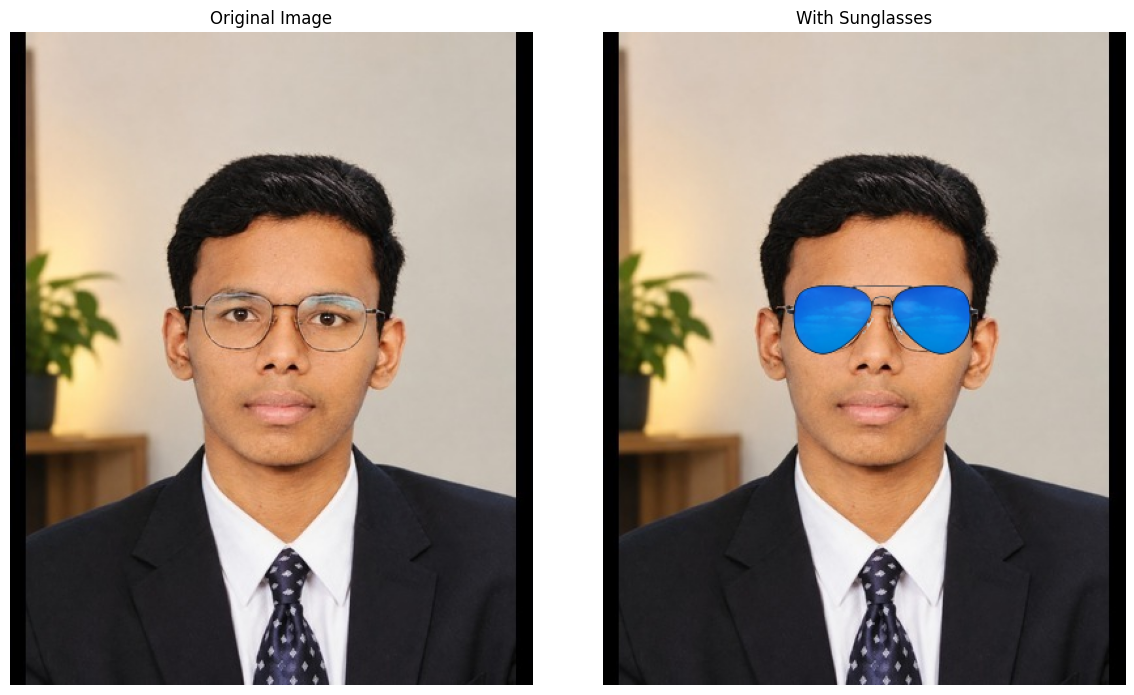

Saved as face_with_sunglasses.png


In [34]:
# Display the original and final images side by side
plt.figure(figsize=(12, 7))

plt.subplot(1, 2, 1)
plt.imshow(faceImage)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(faceWithGlassesArithmetic)
plt.title("With Sunglasses")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the final image
cv2.imwrite(
    "face_with_sunglasses.png",
    cv2.cvtColor(
        faceWithGlassesArithmetic,
        cv2.COLOR_RGB2BGR
    )
)

print("Saved as face_with_sunglasses.png")